**Diabetes Disease Progression Prediction**

The goal is to develop, evaluate, and optimize supervised machine learning regression models to predict diabetes disease progression using the Diabetes dataset from scikit-learn.

In [1]:
#Import Libraries and Load the Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (mean_squared_error, mean_absolute_error, r2_score)

# Load Diabetes dataset
diabetes = load_diabetes()

# Convert features into DataFrame
df = pd.DataFrame(diabetes.data, columns=diabetes.feature_names)

# Add target variable
df["target"] = diabetes.target

# Display first five rows
print(df.head())

# Dataset dimensions
print("Dataset shape:", df.shape)


        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
Dataset shape: (442, 11)


In [2]:
#Explore the dataset

# Dataset information
df.info()

# Descriptive statistics
print(df.describe())

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check duplicates
print("Duplicate rows:", df.duplicated().sum())

# Target distribution
print(df["target"].describe())


<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
                age           sex           bmi            bp            s1  \
count  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02  4.420000e+02   
mean  -2.511817e-19  1.230790e-17 -2.245564e-16 -4.797570e-17 -1.381499e-17   
std    4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02  4.761905e-02   
min   -1.072256e-01 -4.464164e-02 -9.027530e-02 -1.123988e-01 -1.26

There are no missing values, and  no duplicates

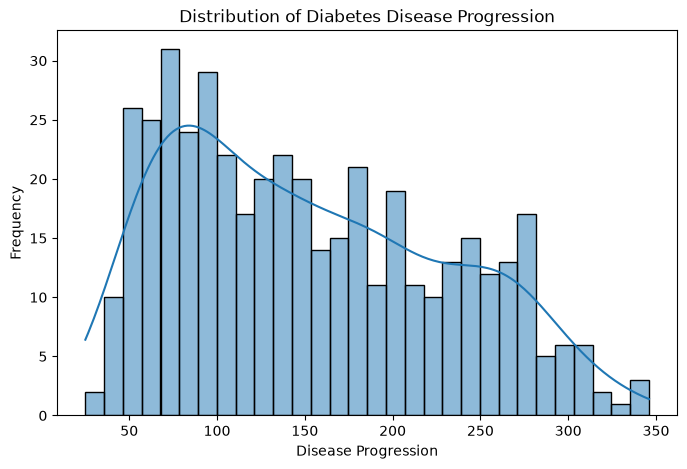

In [3]:
#Visualize the target distribution

plt.figure(figsize=(8, 5))

sns.histplot(df["target"], bins=30, kde=True)

plt.title("Distribution of Diabetes Disease Progression")
plt.xlabel("Disease Progression")
plt.ylabel("Frequency")

plt.show()


Based on the histogram, most patients have progression scores between approximately 50 and 150.The highest concentration occurs around 60–100, indicating that lower progression scores are relatively common.

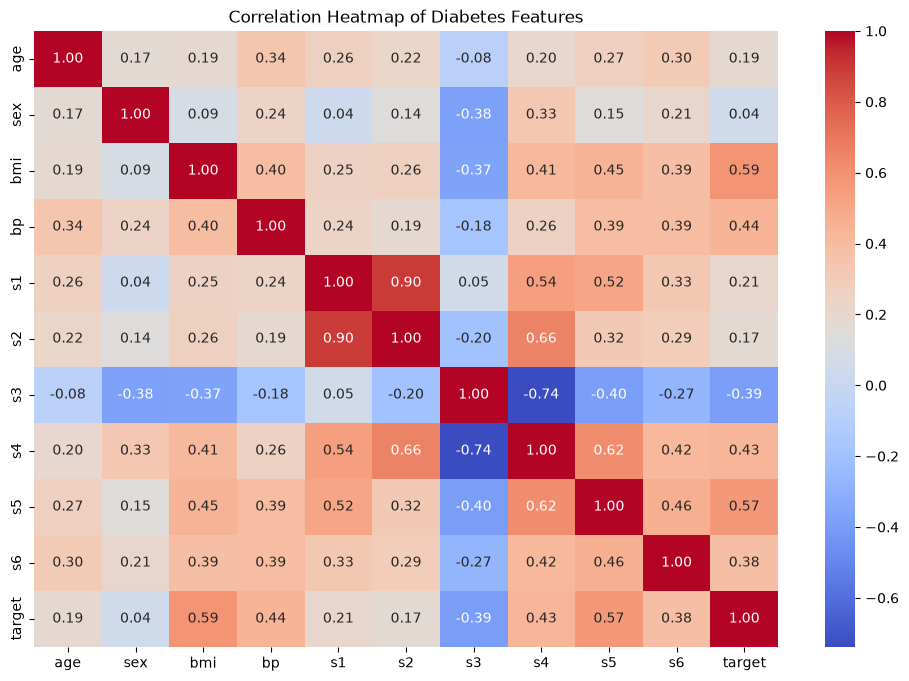

In [4]:
#Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap of Diabetes Features")
plt.show()


The corelation coefficients ranges from -1 to 1. With -1 representing negatve correlation and 1 represent positive correlation. This means that every feature compared with itself always have a positive corelation (the red section with 1 as coefficient). However when compared with other features such as the target, it shows how that feature is correlated with the other feature,
exampled. BMI compared with target shows the highest positive corelation is 0.59. this means that higher BMI values tend to have higher diebetes disease progreesion scores.

In [5]:
#separate features and target and split the dataset

# Separate features and target
X = df.drop("target", axis=1)
y = df["target"]

# Ensure numerical data types
X = X.astype(float)

# Split dataset (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

# Standardize using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed.")


Training samples: 353
Testing samples: 89
Feature scaling completed.


note that splitting before preprocessing prevents data leakage. Also, there are no missing values, and no data inconsistency, therefor eno need for data cleaning.

In [6]:
#Model Selection and Training

models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Lasso Regression": Lasso(alpha=0.1, max_iter=10000),
    "Decision Tree": DecisionTreeRegressor(
        max_depth=4,
        random_state=42
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42
    )
}

# Store trained models
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    trained_models[name] = pipeline

    print(f"{name} trained successfully.")



Linear Regression trained successfully.
Ridge Regression trained successfully.
Lasso Regression trained successfully.
Decision Tree trained successfully.
Random Forest trained successfully.


In [7]:
#Evaluate Model Performance

results = []

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)

    results.append({
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "MAE": mae,
        "R2 Score": r2
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="RMSE"
).reset_index(drop=True)

print(results_df.round(4))


               Model        MSE     RMSE      MAE  R2 Score
0   Lasso Regression  2884.6243  53.7087  42.8052    0.4555
1   Ridge Regression  2892.0146  53.7775  42.8120    0.4541
2  Linear Regression  2900.1936  53.8534  42.7941    0.4526
3      Random Forest  2959.1806  54.3984  44.1712    0.4415
4      Decision Tree  3568.9653  59.7408  47.0454    0.3264


MSE measures the average squared difference between actual and predicted values. Lower is better. 
RMSE measures the typical magnitude of prediction errors in the same units as the target. Lower is better.
MAE measures the average absolute difference between actual and predicted values. Lower is better.
R² Score measures how much of the variation in disease progression the model explains. Higher is better.

Therefore, Lasso has the best overal performance with lowest MSE (2884.62), and RMSE (53.71), highest R² score of 0.4555. The R² score indicates that the model explains approximately 45.55% of the variation in diabetes progression scores.

Random Forest achieved a slightly lower R² score of 0.4415, while Decision Tree had the weakest performance with an R² score of 0.3264.

**Visualize model performance using plots **

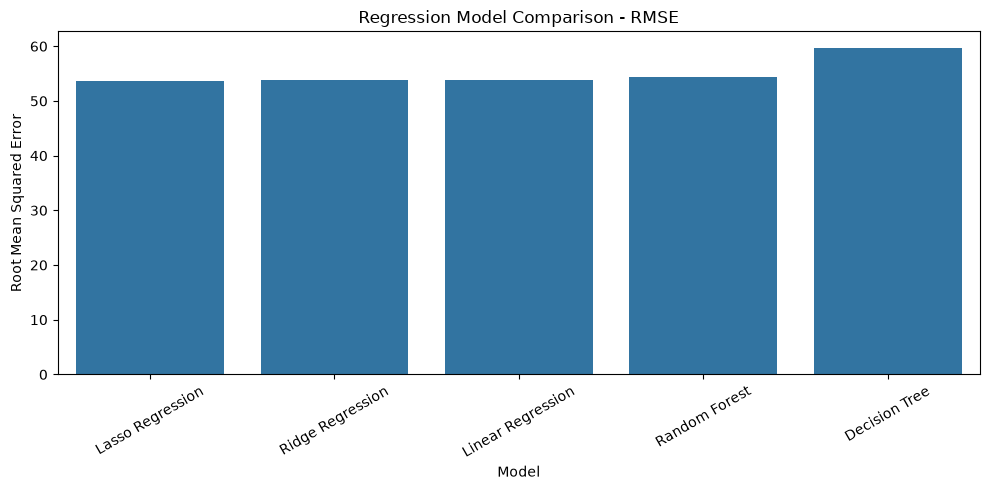

In [8]:
#Barchart
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Regression Model Comparison - RMSE")
plt.ylabel("Root Mean Squared Error")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()


The lowest RMSE indicated a better model but the bars are almost the same hieght for the Lasso, Ridge, linear and random forest this is because the differences between Lasso, Ridge, and Linear Regression are very small and insinificant. Even though the lasso regression shows the lowest,  to better undetstand if it is the best model, A Hyper parameter tuning will be completed before concluding that Lasso consistently performs best

**Hyperparameter Tuning and Optimization**
Hyperparameter tuning improves model performance by searching for suitable parameter combinations

In [9]:

param_grids = {
    "Ridge Regression": {
        "model__alpha": [0.01, 0.1, 1, 10, 100]
    },

    "Lasso Regression": {
        "model__alpha": [0.01, 0.1, 1, 5, 10]
    },

    "Decision Tree": {
        "model__max_depth": [2, 3, 4, 5, 6],
        "model__min_samples_split": [2, 5, 10]
    },

    "Random Forest": {
        "model__n_estimators": [50, 100, 200],
        "model__max_depth": [3, 5, 10, None],
        "model__min_samples_split": [2, 5]
    }
}

tuned_models = {}
tuning_results = []

for name, grid in param_grids.items():

    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("model", models[name])
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=grid,
        cv=5,
        scoring="neg_mean_squared_error",
        n_jobs=-1
    )

    search.fit(X_train, y_train)

    tuned_models[name] = search.best_estimator_

    tuning_results.append({
        "Model": name,
        "CV RMSE": np.sqrt(-search.best_score_),
        "Best Parameters": search.best_params_
    })

    print(f"\n{name}")
    print("Best parameters:", search.best_params_)
    print("Cross-validation RMSE:", np.sqrt(-search.best_score_))

tuning_df = pd.DataFrame(tuning_results)
display(tuning_df)



Ridge Regression
Best parameters: {'model__alpha': 10}
Cross-validation RMSE: 55.928500771403385

Lasso Regression
Best parameters: {'model__alpha': 1}
Cross-validation RMSE: 55.950496254037006

Decision Tree
Best parameters: {'model__max_depth': 2, 'model__min_samples_split': 2}
Cross-validation RMSE: 61.43653552107067

Random Forest
Best parameters: {'model__max_depth': 3, 'model__min_samples_split': 5, 'model__n_estimators': 200}
Cross-validation RMSE: 58.405335525882904


,Model,CV RMSE,Best Parameters
0,Ridge Regression,55.928501,{'model__alpha': 10}
1,Lasso Regression,55.950496,{'model__alpha': 1}
2,Decision Tree,61.436536,"{'model__max_depth': 2, 'model__min_samples_sp..."
3,Random Forest,58.405336,"{'model__max_depth': 3, 'model__min_samples_sp..."


Cross-validation RMSE measures the average prediction error across validation folds. A lower RMSE indicates better predictive performance. Based on the scores, Ridge Regression performed the best model at 55.92 based on cross-validation performance, although its advantage over Lasso at 55.95 is extremely small.

In [11]:
#Compare Tuned Models and Select the Best Model

# Include baseline Linear Regression
candidate_models = {
    "Linear Regression": trained_models["Linear Regression"],
    **tuned_models
}

cv_results = []

for name, model in candidate_models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_mean_squared_error"
    )

    cv_rmse = np.sqrt(-scores.mean())

    cv_results.append({
        "Model": name,
        "CV RMSE": cv_rmse
    })

cv_df = pd.DataFrame(cv_results).sort_values("CV RMSE")

print(cv_df.round(4))

# Select best model using training CV only
best_name = cv_df.iloc[0]["Model"]
best_model = candidate_models[best_name]

# Refit selected model on full training set
best_model.fit(X_train, y_train)

# Final test predictions
y_pred_best = best_model.predict(X_test)

print("\nBest Model:", best_name)
print("Test MSE:", mean_squared_error(y_test, y_pred_best))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, y_pred_best)))
print("Test MAE:", mean_absolute_error(y_test, y_pred_best))
print("Test R2:", r2_score(y_test, y_pred_best))


               Model  CV RMSE
1   Ridge Regression  55.9285
2   Lasso Regression  55.9505
0  Linear Regression  56.0626
4      Random Forest  58.4053
3      Decision Tree  61.4365

Best Model: Ridge Regression
Test MSE: 2875.778718421844
Test RMSE: 53.6262875688952
Test MAE: 42.856825247800614
Test R2: 0.45721095677808465


After the cross validation to improve the model performance, the Ridge Regression performed the best even thouse its difference with the Lasso is very insignificant.

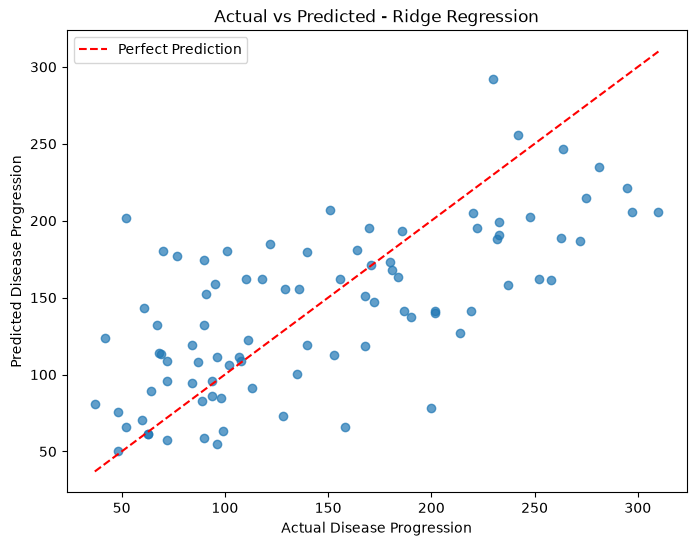

In [12]:
#Visualize the Actual vs predicted

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred_best,
    alpha=0.7
)

limits = [
    min(y_test.min(), y_pred_best.min()),
    max(y_test.max(), y_pred_best.max())
]

plt.plot(limits, limits, "r--", label="Perfect Prediction")

plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title(f"Actual vs Predicted - {best_name}")
plt.legend()

plt.show()


Points closer to the red diagonal line indicate more accurate predictions. Points farther away indicate larger prediction errors. A good model should produce predictions that follow the diagonal without systematic or huge deviations. 

**Residual Analysis**
Residuals are the differences between actual and predicted values

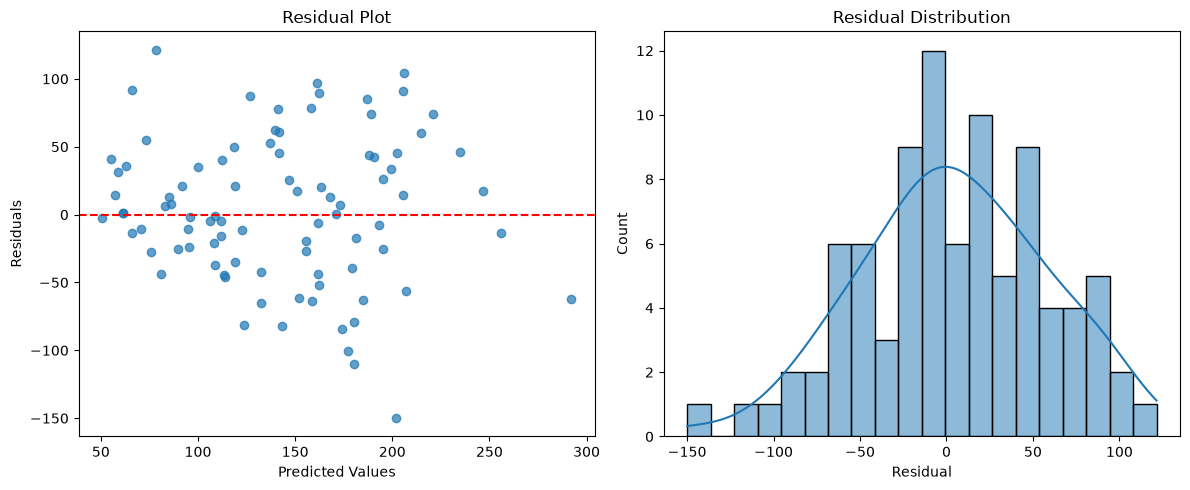

In [13]:
residuals = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Residual scatterplot
axes[0].scatter(y_pred_best, residuals, alpha=0.7)
axes[0].axhline(0, color="red", linestyle="--")

axes[0].set_xlabel("Predicted Values")
axes[0].set_ylabel("Residuals")
axes[0].set_title("Residual Plot")

# Residual distribution
sns.histplot(residuals, bins=20, kde=True, ax=axes[1])

axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual")

plt.tight_layout()
plt.show()
